# Where should observations be added to an existing ocean network?

## 1. The question and the corrected design

**Keep the observed network. Add the same number of observations in two different ways. Measure the change on the same hidden evaluation cells.**

The earlier study replaced historical-density, random and coverage sampling with one another at a fixed total sample count. This pilot instead preserves a common baseline H and asks whether **1,000 additional month-cells in historical gaps** improve reconstruction more than **1,000 random additional month-cells**.

The baseline uses actual 2005 SOCAT observation locations mapped onto the existing model grid, rather than a fresh density-weighted sample. Every baseline location remains in both augmented arms. The observation values are idealized pCO2 values from IPSL-CM6A-LR; this is an observing-system simulation experiment, not validation against measured ocean CO2.

This new protocol was fixed before its model runs, after previous replacement-strategy results were known. It is a one-year exploratory pilot. The notebook reads completed results and regenerates figures only; Run All does not train models or acquire observations.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
HERE = Path.cwd()
assert (HERE / "results/completed.json").exists(), "Run this notebook from its study directory"
OUT = HERE / "results"
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
completed = json.loads((OUT / "completed.json").read_text())
started = json.loads((OUT / "started.json").read_text())
assert sha(OUT / "started.json") == completed["started_sha256"]
for relative, expected in completed["outputs_sha256"].items():
    assert sha(OUT / relative) == expected, relative
for relative, expected in started["study_inputs_sha256"].items():
    assert sha(HERE / relative) == expected, relative
cfg, inventory = started["config"], started["inventory"]
design = pd.read_parquet(OUT / "design.parquet")
additions = pd.read_csv(OUT / "additions.csv")
pred = pd.read_parquet(OUT / "evaluation_predictions.parquet")
scores = pd.read_csv(OUT / "metrics.csv")
effects = pd.read_csv(OUT / "paired_effects.csv")
summary = pd.read_csv(OUT / "effect_summary.csv")
BLUE, ORANGE, GRAY = "#147DB3", "#DE5B2D", "#687B83"
arms = ["baseline", "random_addition", "gap_addition"]
labels = {"baseline": "Existing network", "random_addition": "H + random", "gap_addition": "H + gap"}
colors = {"baseline": GRAY, "random_addition": BLUE, "gap_addition": ORANGE}
domains = ["global_unobserved", "historical_gap", "previously_observed_locations"]
domain_labels = {"global_unobserved": "Global unobserved domain", "historical_gap": "Historical gaps",
                 "previously_observed_locations": "Previously observed locations"}
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "svg.fonttype": "none", "svg.hashsalt": "ocean-augmentation-2005", "figure.dpi": 150})
def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(FIG / f"{name}.svg", bbox_inches="tight", metadata={"Date": None})
print("Completed result hashes and pre-fit study inputs verified; no fitting performed.")

Completed result hashes and pre-fit study inputs verified; no fitting performed.


## 2. Data and the existing network

[SOCAT v2025](https://doi.org/10.25921/648f-fv35) supplies the month and location of valid observations. A valid entry has a positive observation count and finite fCO2. We use those entries to define coverage; measured fCO2 values are not the regression target.

[IPSL-CM6A-LR historical r1i1p1f1](https://doi.org/10.22033/ESGF/CMIP6.5195) supplies complete-case monthly pCO2, sea-surface temperature and salinity on the existing processed 1-degree grid. pCO2 and fCO2 are distinct quantities. No artificial measurement noise or physical-accessibility filter is added.

H contains all matched **2005 month-location pairs**, with one idealized observation per model month-cell. Actual cruise counts and repeated measurements are not reproduced. Unmatched SOCAT cells are reported below rather than interpolated. The study includes the available complete-case global grid, including latitudes north of 60°N; it is distinct from the older latitude-restricted headline analysis.

In [2]:
display(pd.DataFrame([
    ["Year", cfg["year"]],
    ["Valid SOCAT month-cells in year", inventory["socat_2005_valid_month_cells"]],
    ["Matched fixed baseline H", inventory["matched_baseline_month_cells"]],
    ["Unmatched SOCAT month-cells", inventory["unmatched_socat_month_cells"]],
    ["Complete model month-cells", len(design)],
    ["Fixed hidden evaluation cells", len(pred)],
    ["Evaluation cells in historical gaps", int(pred.historical_gap.sum())],
    ["Added month-cells in each augmented arm", cfg["added_month_cells"]],
    ["Acquisition seeds", len(cfg["acquisition_seeds"])],
], columns=["Design item", "Count"]))
display(Markdown(f"The existing network contains **{inventory['matched_baseline_month_cells']:,}** matched month-cells. "
    f"Each augmented fit uses **{inventory['matched_baseline_month_cells'] + cfg['added_month_cells']:,}** cells; "
    f"all arms are evaluated on the same **{len(pred):,}** hidden cells."))

,Design item,Count
0,Year,2005
1,Valid SOCAT month-cells in year,11961
2,Matched fixed baseline H,11676
3,Unmatched SOCAT month-cells,285
4,Complete model month-cells,487488
5,Fixed hidden evaluation cells,95156
6,Evaluation cells in historical gaps,49344
7,Added month-cells in each augmented arm,1000
8,Acquisition seeds,5


The existing network contains **11,676** matched month-cells. Each augmented fit uses **12,676** cells; all arms are evaluated on the same **95,156** hidden cells.

## 3. What counts as a historical gap?

A historical gap is a **1-degree spatial location with no valid SOCAT record in any month during 1990–2005**. It is not merely a missing season, and it does not mean no observation has ever been made there outside that archive/window.

The two augmented arms add 1,000 observations each, with equal month quotas: 84 in January–April and 83 in May–December. H+random samples all eligible remaining cells; H+gap samples only historical-gap locations. Both sample without replacement and never use target values or baseline errors to choose points.

The map below fixes acquisition seed 0 in advance. It displays grid-cell centres, pooled over the twelve months. Multiple month-cells can overlap at one plotted position; these are neither ship tracks nor a deployment plan.

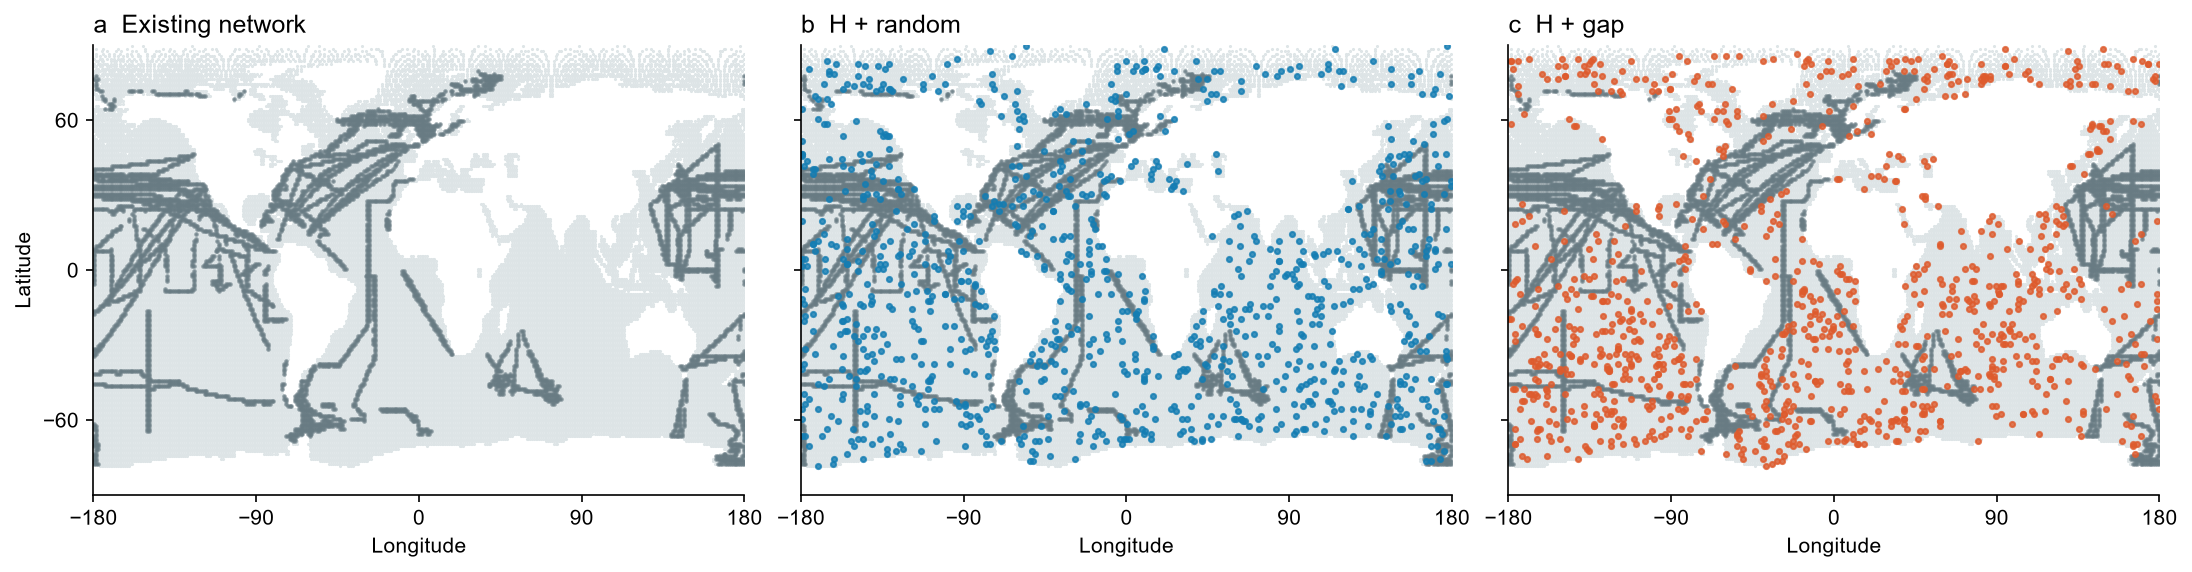

All H records preserved; no evaluation cell acquired; all added month quotas identical.


In [3]:
baseline_ids = set(design.loc[design.baseline, "cell_id"])
evaluation_ids = set(pred.cell_id)
assert baseline_ids.isdisjoint(evaluation_ids)
assert evaluation_ids == set(design.loc[design.evaluation, "cell_id"])
assert pred.cell_id.is_unique
for (seed, arm), group in additions.groupby(["seed", "arm"]):
    ids = set(group.cell_id)
    assert len(ids) == len(group) == cfg["added_month_cells"]
    assert ids.isdisjoint(baseline_ids) and ids.isdisjoint(evaluation_ids)
    assert arm != "gap_addition" or group.historical_gap.all()
    assert len(baseline_ids | ids) == len(baseline_ids) + cfg["added_month_cells"]
    expected = [84]*4 + [83]*8
    assert group.groupby("month").size().reindex(range(1,13)).tolist() == expected
assert additions.groupby(["seed", "arm"]).ngroups == 10
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.7), sharex=True, sharey=True, layout="constrained")
background = design[["longitude", "latitude"]].drop_duplicates()
base = design.loc[design.baseline, ["longitude", "latitude"]].drop_duplicates()
for i, (ax, arm) in enumerate(zip(axes, arms)):
    ax.scatter(background.longitude, background.latitude, s=.25, color="#DDE4E6", rasterized=True)
    ax.scatter(base.longitude, base.latitude, s=1.5, color=GRAY, alpha=.65, rasterized=True)
    if arm != "baseline":
        added = additions.loc[additions.seed.eq(0) & additions.arm.eq(arm)]
        ax.scatter(added.longitude, added.latitude, s=6, color=colors[arm], alpha=.8, rasterized=True)
    ax.set_title(f"{chr(97+i)}  {labels[arm]}", loc="left")
    ax.set(xlim=(-180,180), ylim=(-90,90), xlabel="Longitude")
    ax.set_xticks([-180,-90,0,90,180])
    ax.set_yticks([-60,0,60])
axes[0].set_ylabel("Latitude")
savefig(fig, "network_additions")
plt.show()
print("All H records preserved; no evaluation cell acquired; all added month quotas identical.")

## 4. Common evaluation and a fixed reconstruction method

Before choosing new samples, 20% of non-H month-cells were hidden within each month × gap-status stratum. Every arm shares that evaluation set, which remains unavailable for acquisition. A location can have other months in training: the task is missing-month-cell reconstruction, not transfer to wholly unseen spatial blocks.

The primary measure is **area-weighted RMSE over the global unobserved domain**. We also report MAE and signed bias, plus results separately for historical-gap locations and previously observed locations. Weights combine spherical grid-cell area with inverse evaluation-inclusion probability. No extreme target values are removed.

All arms use the same HistGradientBoosting model and features: SST, salinity, latitude, cyclic longitude, year and cyclic month. The existing learning rate, tree size and regularization are retained; all fits use 150 iterations with early stopping disabled. The year feature is constant within this one-year study. Model randomness is fixed, so the five paired seeds vary only the added samples.

H is fitted once, with its predictions reused as the common baseline. Five seeds for each augmentation give **11 fits**, not 15 independent model replicates. The notebook recomputes every reported score from saved predictions below.

rmse     mae   bias
domain                        arm                                   
global_unobserved             baseline         38.791  15.537  1.173
                              gap_addition     35.665  12.371  0.141
                              random_addition  36.127  12.646  0.372
historical_gap                baseline         53.060  19.345  0.855
                              gap_addition     49.073  14.366 -0.192
                              random_addition  49.857  15.146  0.191
previously_observed_locations baseline         17.155  12.021  1.467
                              gap_addition     14.919  10.529  0.449
                              random_addition  14.658  10.336  0.538

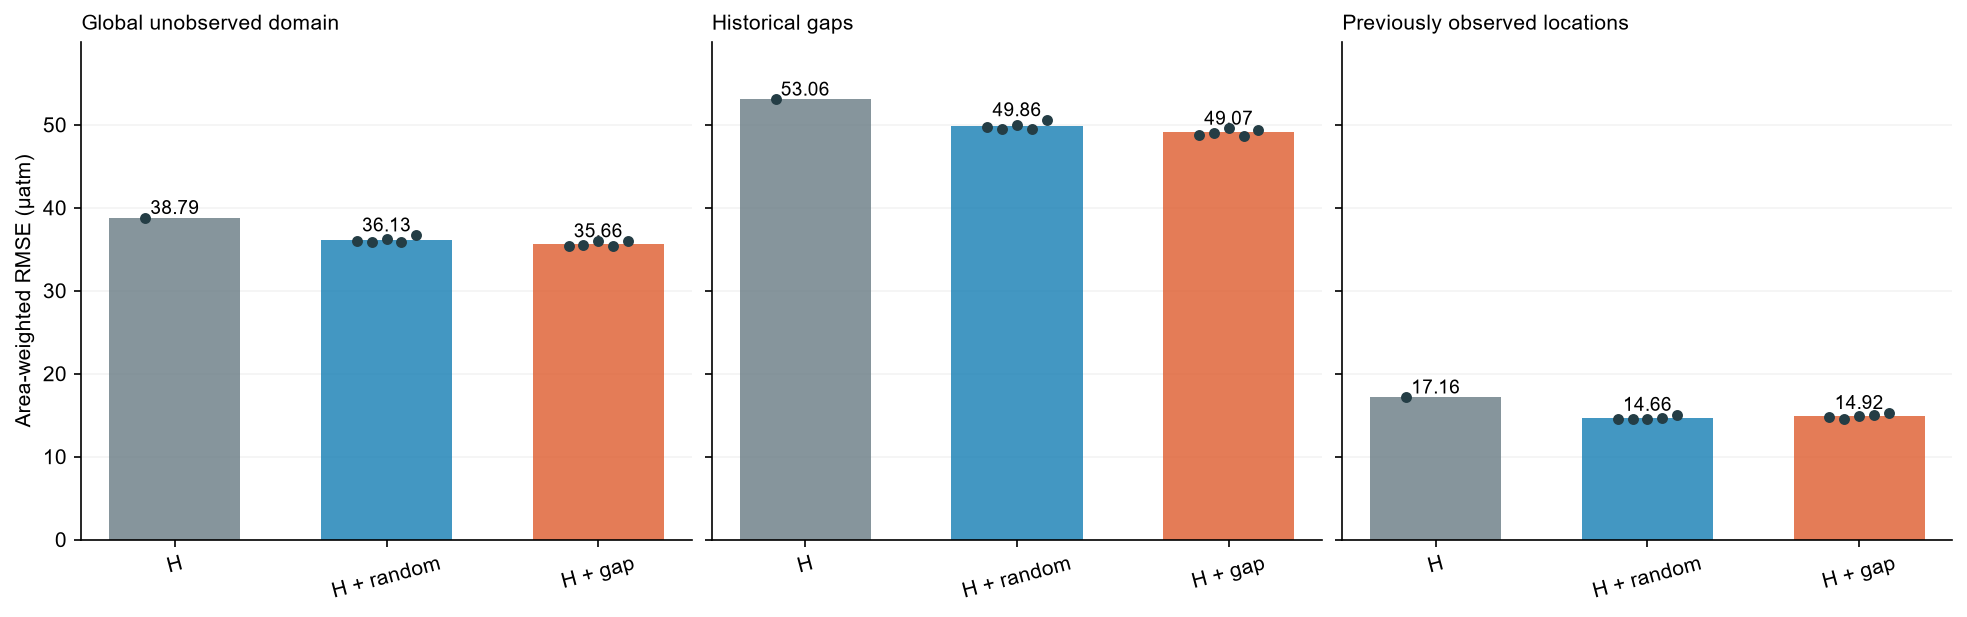

In [4]:
assert completed["model_fits"] == 11 and len(scores) == 33
for row in scores.itertuples():
    column = "baseline" if row.arm == "baseline" else f"{row.arm}_seed_{row.seed}"
    mask = np.ones(len(pred), bool) if row.domain == "global_unobserved" else (
        pred.historical_gap.to_numpy() if row.domain == "historical_gap" else ~pred.historical_gap.to_numpy())
    residual = pred.loc[mask, column].to_numpy() - pred.loc[mask, "truth"].to_numpy()
    weight = pred.loc[mask, "weight"].to_numpy()
    assert np.isclose(np.sqrt(np.average(residual**2, weights=weight)), row.rmse)
    assert np.isclose(np.average(abs(residual), weights=weight), row.mae)
    assert np.isclose(np.average(residual, weights=weight), row.bias)
    expected_train = len(baseline_ids) + (0 if row.arm == "baseline" else cfg["added_month_cells"])
    assert row.n_training == expected_train and row.n_evaluation == int(mask.sum())
table = scores.groupby(["domain", "arm"])[["rmse", "mae", "bias"]].mean()
display(table.round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout="constrained")
for ax, domain in zip(axes, domains):
    for i, arm in enumerate(arms):
        values = scores.loc[scores.domain.eq(domain) & scores.arm.eq(arm), "rmse"].to_numpy()
        ax.bar(i, values.mean(), width=.62, color=colors[arm], alpha=.8)
        ax.scatter(i + np.linspace(-.14,.14,len(values)), values, color="#243D45", s=18, zorder=4)
        ax.text(i, values.max()+.45, f"{values.mean():.2f}", ha="center", fontsize=9)
    ax.set_xticks(range(3), ["H", "H + random", "H + gap"], rotation=15)
    ax.set_title(domain_labels[domain], fontsize=10, loc="left")
    ax.grid(axis="y", alpha=.15)
    ax.set_axisbelow(True)
    ax.set_ylim(0, scores.rmse.max()*1.13)
axes[0].set_ylabel("Area-weighted RMSE (µatm)")
savefig(fig, "reconstruction_errors")
plt.show()

**Figure 2.** Mean RMSE for each arm; dots show all five acquisition seeds for augmented arms and the single fixed baseline. No confidence intervals or significance tests are implied. The subgroup denominators differ, so compare arms within each panel.

## 5. Does adding observations help, and does gap targeting help more?

Three paired contrasts answer different questions: **H minus H+random**, **H minus H+gap**, and **H+random minus H+gap**. Positive RMSE/MAE differences favor the added observations or gap targeting. A gain over H alone does not establish that gap targeting is better than equal-count random additions.

Every seed is retained. The displayed mean and minimum–maximum range summarize acquisition randomness conditional on this year, model field, network, learner and evaluation sample. They are not confidence intervals for real-ocean performance.

,domain,metric,contrast,mean_improvement,min_improvement,max_improvement,n_seeds,positive_seeds
0,global_unobserved,mae,baseline_minus_gap,3.166,2.812,3.499,5,5
1,global_unobserved,mae,baseline_minus_random,2.892,2.485,3.036,5,5
2,global_unobserved,mae,random_minus_gap,0.274,0.021,0.526,5,5
3,global_unobserved,rmse,baseline_minus_gap,3.126,2.807,3.370,5,5
4,global_unobserved,rmse,baseline_minus_random,2.664,2.100,2.946,5,5
5,global_unobserved,rmse,random_minus_gap,0.462,0.241,0.732,5,5
6,historical_gap,mae,baseline_minus_gap,4.979,4.496,5.409,5,5
7,historical_gap,mae,baseline_minus_random,4.198,3.764,4.434,5,5
8,historical_gap,mae,random_minus_gap,0.780,0.413,1.141,5,5
9,historical_gap,rmse,baseline_minus_gap,3.987,3.503,4.391,5,5


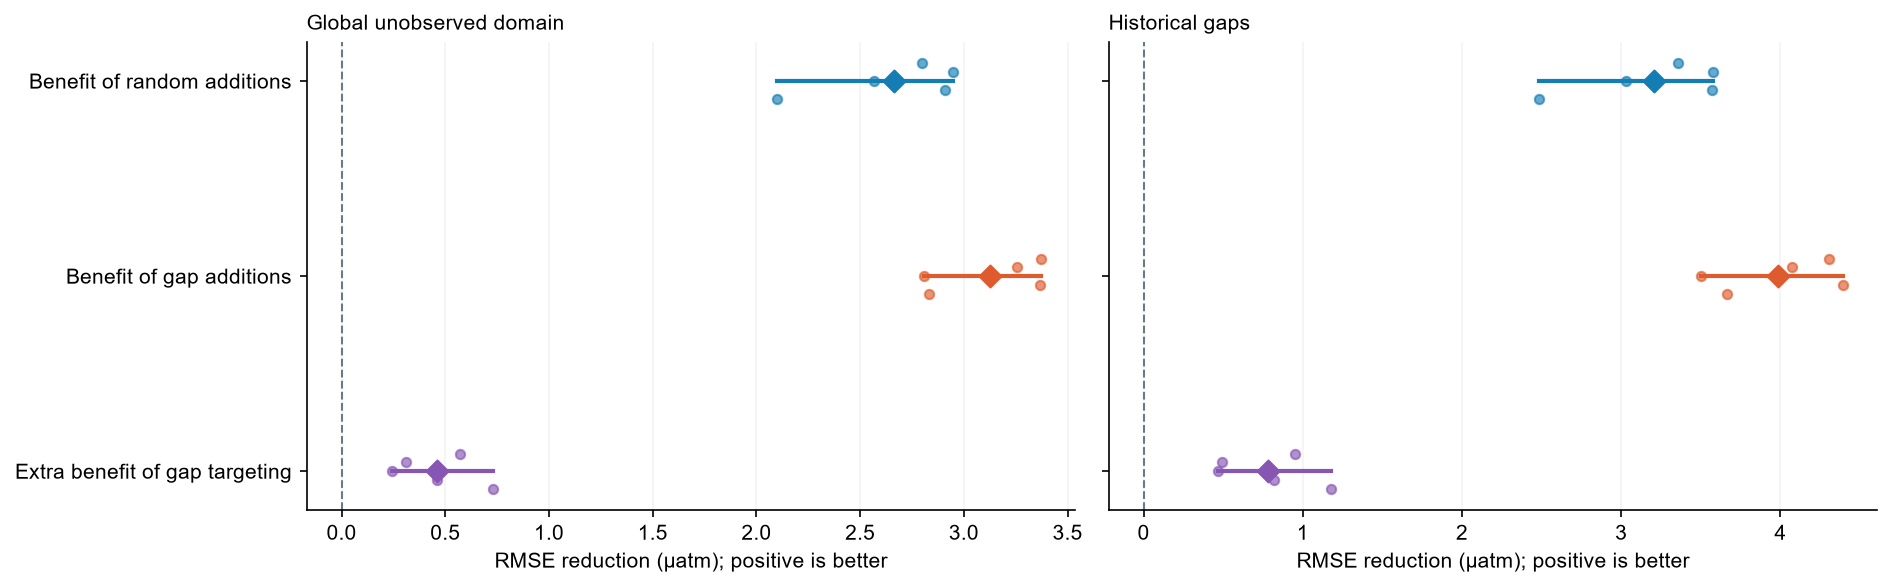

**Global unobserved domain**

Benefit of random additions: **+2.664 µatm**, seed range +2.100 to +2.946; 5/5 seeds positive.

Benefit of gap additions: **+3.126 µatm**, seed range +2.807 to +3.370; 5/5 seeds positive.

Extra benefit of gap targeting: **+0.462 µatm**, seed range +0.241 to +0.732; 5/5 seeds positive.

**Historical gaps**

Benefit of random additions: **+3.204 µatm**, seed range +2.482 to +3.578; 5/5 seeds positive.

Benefit of gap additions: **+3.987 µatm**, seed range +3.503 to +4.391; 5/5 seeds positive.

Extra benefit of gap targeting: **+0.783 µatm**, seed range +0.471 to +1.180; 5/5 seeds positive.

In [5]:
for row in effects.itertuples():
    group = scores.loc[scores.domain.eq(row.domain)]
    b = group.loc[group.arm.eq("baseline"), row.metric].iloc[0]
    r = group.loc[group.arm.eq("random_addition") & group.seed.eq(row.seed), row.metric].iloc[0]
    g = group.loc[group.arm.eq("gap_addition") & group.seed.eq(row.seed), row.metric].iloc[0]
    assert np.isclose(row.improvement, {"baseline_minus_random": b-r, "baseline_minus_gap": b-g,
                                       "random_minus_gap": r-g}[row.contrast])
display(summary.round(3))
names = ["baseline_minus_random", "baseline_minus_gap", "random_minus_gap"]
contrast_labels = ["Benefit of random additions", "Benefit of gap additions", "Extra benefit of gap targeting"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), layout="constrained", sharey=True)
for ax, domain in zip(axes, domains[:2]):
    for i, (contrast, color) in enumerate(zip(names, [BLUE, ORANGE, "#8756B3"])):
        values = effects.loc[effects.domain.eq(domain) & effects.metric.eq("rmse") & effects.contrast.eq(contrast), "improvement"].to_numpy()
        ax.plot([values.min(),values.max()], [i,i], color=color, lw=2)
        ax.scatter(values, i+np.linspace(-.09,.09,len(values)), s=20, color=color, alpha=.65)
        ax.scatter([values.mean()], [i], marker="D", color=color, s=55, zorder=4)
    ax.axvline(0, color=GRAY, ls="--", lw=1)
    ax.set_title(domain_labels[domain], fontsize=10, loc="left")
    ax.set_xlabel("RMSE reduction (µatm); positive is better")
    ax.grid(axis="x", alpha=.15)
axes[0].set_yticks(range(3), contrast_labels)
axes[0].invert_yaxis()
savefig(fig, "paired_augmentation_effects")
plt.show()
for domain in domains[:2]:
    lines = []
    for contrast, label in zip(names, contrast_labels):
        row = summary.loc[summary.domain.eq(domain) & summary.metric.eq("rmse") & summary.contrast.eq(contrast)].iloc[0]
        lines.append(f"{label}: **{row.mean_improvement:+.3f} µatm**, seed range "
                     f"{row.min_improvement:+.3f} to {row.max_improvement:+.3f}; "
                     f"{int(row.positive_seeds)}/{int(row.n_seeds)} seeds positive.")
    display(Markdown("**" + domain_labels[domain] + "**\n\n" + "\n\n".join(lines)))

**Figure 3.** All five paired RMSE effects, with a diamond for the mean and a line spanning the observed seed range. Global and gap-domain results are both shown; the table retains the previously observed-location domain and MAE contrasts.

## 6. What can be concluded from this pilot?

The numerical statements below are generated from the saved primary contrasts, using all five seeds. They distinguish improvement over the existing network from an advantage over random additions. They describe mean effects and seed consistency, not statistical significance.

In [6]:
primary = summary.loc[summary.domain.eq("global_unobserved") & summary.metric.eq("rmse")].set_index("contrast")
gap_gain = primary.loc["baseline_minus_gap"]
target_gain = primary.loc["random_minus_gap"]
first = ("Gap additions reduce" if gap_gain.mean_improvement > 0 else "Gap additions do not reduce")
second = ("Gap targeting has lower" if target_gain.mean_improvement > 0 else "Gap targeting does not have lower")
display(Markdown(
    f"**{first} mean global hidden-cell RMSE relative to H** "
    f"(reduction {gap_gain.mean_improvement:+.3f} µatm; {int(gap_gain.positive_seeds)}/5 seeds positive). "
    f"**{second} mean RMSE than equal-count random additions** "
    f"(random minus gap {target_gain.mean_improvement:+.3f} µatm; {int(target_gain.positive_seeds)}/5 seeds positive)."))
print("No sampling strategy, evaluation domain or model setting was changed after seeing these results.")

**Gap additions reduce mean global hidden-cell RMSE relative to H** (reduction +3.126 µatm; 5/5 seeds positive). **Gap targeting has lower mean RMSE than equal-count random additions** (random minus gap +0.462 µatm; 5/5 seeds positive).

No sampling strategy, evaluation domain or model setting was changed after seeing these results.


## 7. Boundaries and next step

This pilot answers a counterfactual question about **adding idealized observations to fixed historical support**. It neither replays ship trajectories nor proves that a real platform could collect the added observations at equal cost. Some historical-gap cells may be inaccessible; the global complete-case domain has no sea-ice or operational mask.

Only one ESM member and one year are used. All predictors and targets share that simulation; observation error and representation error are absent. The test contains missing month-cells, and may share spatial locations with training at other months. The gap definition refers specifically to the 1990–2005 SOCAT archive. The original model-grid preprocessing is retained, so incomplete ocean-bin coverage remains a limitation.

The next extension should freeze several added sample counts and additional years before fitting, then assess whether the pilot's gain and targeting contrast persist. A real-data evaluation would require independent withheld observations and matching inputs; it would answer a separate transfer question. The existing replacement-strategy study remains supporting context, not evidence that the new augmentation question was already answered.

## Reproducibility

- `config.json` and `PROTOCOL.md`: settings and scope fixed before these fits.
- `results/started.json`: pre-fit input/code hashes, data inventory and versions.
- `results/design.parquet` and `additions.csv`: fixed H, evaluation mask and every acquisition.
- `results/evaluation_predictions.parquet`: all hidden truths, weights and predictions for 11 fits.
- `results/metrics.csv`, `paired_effects.csv`, `effect_summary.csv`: all scores and paired summaries.
- `augmentation.py`: explicit experiment runner; refuses to overwrite a started run.
- `test_augmentation.py`: network retention, split exclusion, quota, target-blind support and metric checks.

The English notebook runs from saved results. Rebuilding it does not fit models. Sources: [SOCAT v2025](https://doi.org/10.25921/648f-fv35), [IPSL-CM6A-LR](https://doi.org/10.22033/ESGF/CMIP6.5195). We acknowledge the SOCAT data providers, quality controllers and data managers, and the IPSL/CMIP6 data providers.